In [9]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
DATASET_DIR = "/content/traffic_sign_dataset/traffic_sign"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [10]:
import zipfile
import os

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
ZIP_PATH = os.path.join(PROJECT_DIR, "traffic_sign.zip")
EXTRACT_ROOT = "/content/traffic_sign_dataset"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

print("Extraction complete!")
print("Extracted contents:", os.listdir(EXTRACT_ROOT))

Extraction complete!
Extracted contents: ['traffic_sign']


In [11]:
DATASET_DIR = "/content/traffic_sign_dataset/traffic_sign"
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

print("Train folder exists:", os.path.exists(TRAIN_DIR))
print("Test folder exists:", os.path.exists(TEST_DIR))
print("Train class folders:", len(os.listdir(TRAIN_DIR)))
print("Test class folders:", len(os.listdir(TEST_DIR)))

Train folder exists: True
Test folder exists: True
Train class folders: 85
Test class folders: 85


In [12]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
print("Training images:", len(train_ds.file_paths))
print("Test images:", len(test_ds.file_paths))
print("First 10 classes:", CLASS_NAMES[:10])

Found 4438 files belonging to 85 classes.
Found 1288 files belonging to 85 classes.
Number of classes: 85
Training images: 4438
Test images: 1288
First 10 classes: ['ALL_MOTOR_VEHICLE_PROHIBITED', 'AXLE_LOAD_LIMIT', 'BARRIER_AHEAD', 'BULLOCK_AND_HANDCART_PROHIBITED', 'BULLOCK_PROHIBITED', 'CATTLE', 'COMPULSARY_AHEAD', 'COMPULSARY_AHEAD_OR_TURN_LEFT', 'COMPULSARY_AHEAD_OR_TURN_RIGHT', 'COMPULSARY_CYCLE_TRACK']


In [13]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 85)             │        10,965 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 432,277 (1.65 MB)

 Trainable params: 432,277 (1.65 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")
print("Optimizer: Adam")
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")

Model compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metric: Accuracy


In [15]:
EPOCHS = 50

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    verbose=1
)

Epoch 1/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 62s 348ms/step - accuracy: 0.0721 - loss: 3.7988
Epoch 2/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 59s 264ms/step - accuracy: 0.1543 - loss: 3.1631
Epoch 3/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 42s 272ms/step - accuracy: 0.1884 - loss: 2.9106
Epoch 4/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 38s 276ms/step - accuracy: 0.2434 - loss: 2.6891
Epoch 5/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 36s 259ms/step - accuracy: 0.2693 - loss: 2.5524
Epoch 6/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 262ms/step - accuracy: 0.2693 - loss: 2.4809
Epoch 7/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 40s 257ms/step - accuracy: 0.2862 - loss: 2.4045
Epoch 8/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 258ms/step - accuracy: 0.2968 - loss: 2.3257
Epoch 9/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 259ms/step - accuracy: 0.3166 - loss: 2.2720
Epoch 10/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 262ms/step - accuracy: 0.3357 - loss: 2.1959
Epoch 11/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 42s 273ms/step - accuracy: 0.3477 - loss: 2.1248
Epoch 12/50
139/139

35 min

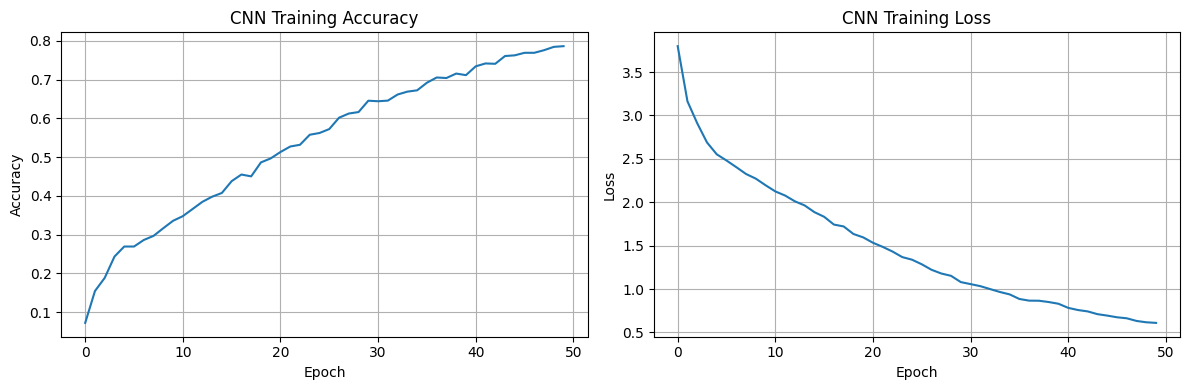

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.title("CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n--- CNN Test Results ---")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 164ms/step - accuracy: 0.7182 - loss: 1.3283

--- CNN Test Results ---
Test Loss: 1.3283
Test Accuracy: 71.82%


41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step
Test Accuracy: 0.7182
Macro Precision: 0.5693
Macro Recall: 0.5499
Macro F1-score: 0.5268

--- Per-class Classification Report ---
                                 precision    recall  f1-score   support

   ALL_MOTOR_VEHICLE_PROHIBITED       0.20      0.20      0.20         5
                AXLE_LOAD_LIMIT       0.50      0.60      0.55         5
                  BARRIER_AHEAD       0.00      0.00      0.00         2
BULLOCK_AND_HANDCART_PROHIBITED       0.25      1.00      0.40         2
             BULLOCK_PROHIBITED       0.67      0.40      0.50         5
                         CATTLE       0.33      0.55      0.41        11
               COMPULSARY_AHEAD       0.40      1.00      0.57        10
  COMPULSARY_AHEAD_OR_TURN_LEFT       0.17      0.25      0.20         4
 COMPULSARY_AHEAD_OR_TURN_RIGHT       0.43      0.25      0.32        12
         COMPULSARY_CYCLE_TRACK       0.50      0.75      0.60         4
           COMPULSARY_KEE

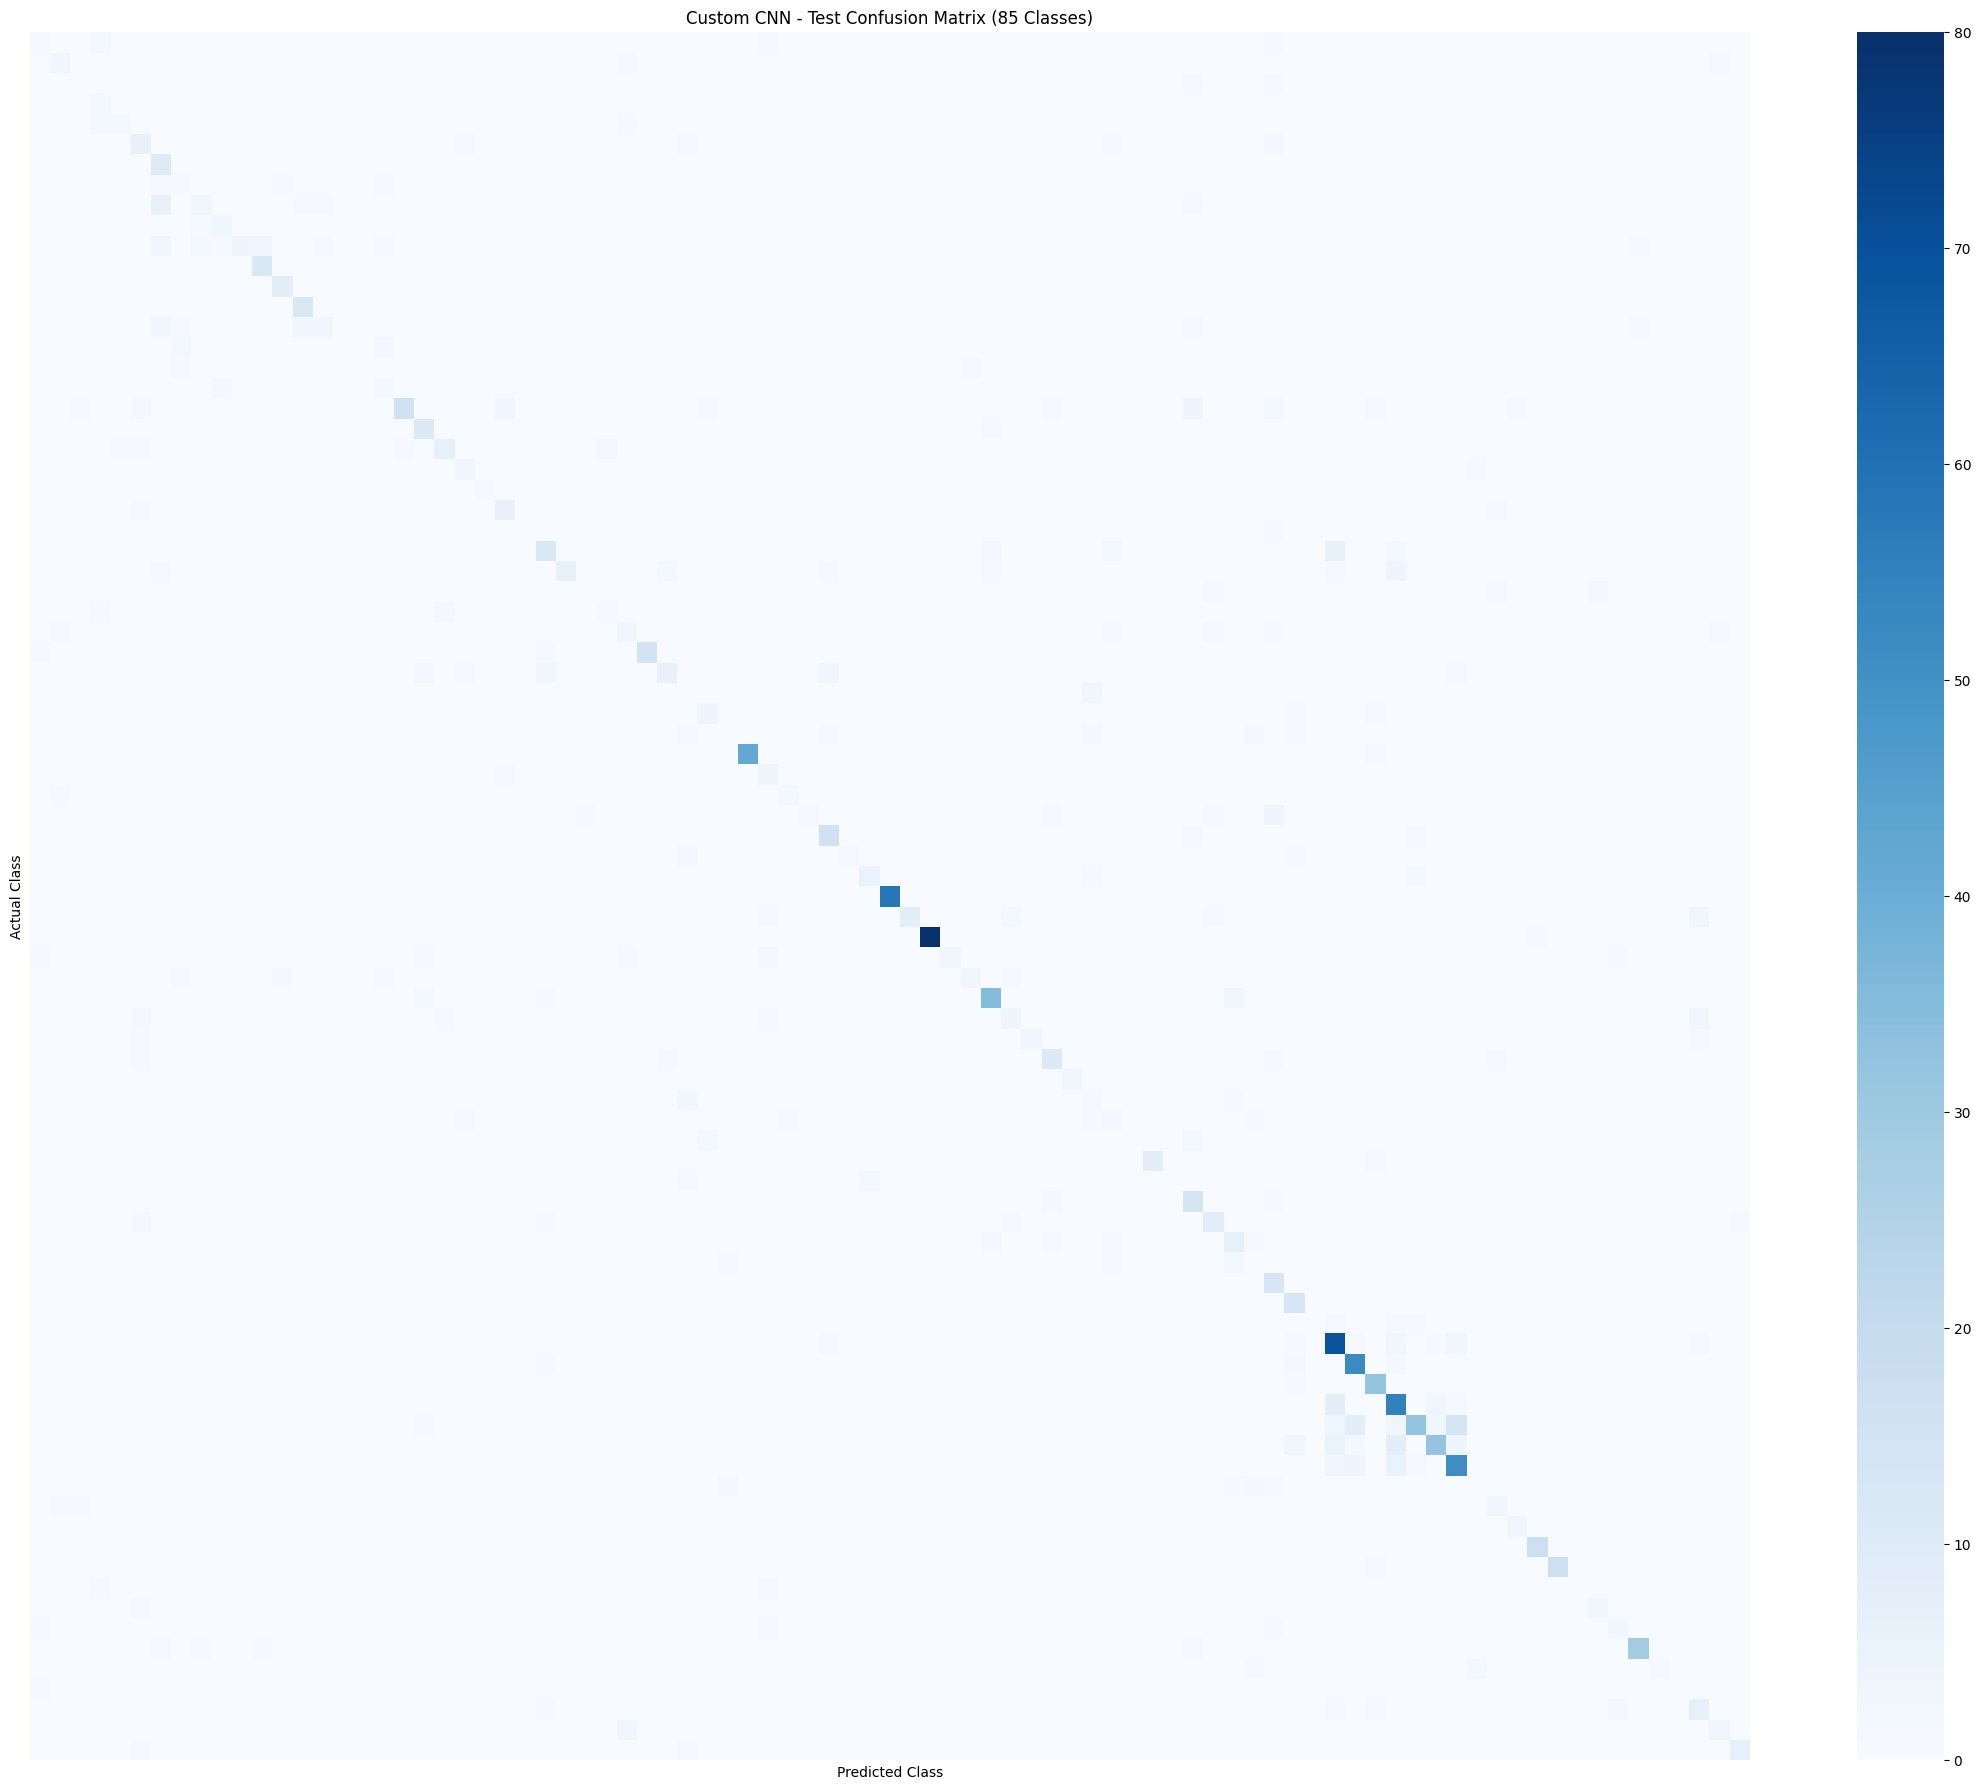

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predicted labels
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Overall metrics
print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro Precision:", round(
    precision_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Macro F1-score:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))

print("\n--- Per-class Classification Report ---")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))

plt.figure(figsize=(22, 18))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("Custom CNN - Test Confusion Matrix (85 Classes)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Remove correct predictions from the confusion matrix
errors = cm.copy()
np.fill_diagonal(errors, 0)

pairs = []
for actual_idx, predicted_idx in zip(*np.where(errors > 0)):
    pairs.append({
        "Actual Sign": CLASS_NAMES[actual_idx],
        "Predicted As": CLASS_NAMES[predicted_idx],
        "Mistakes": int(errors[actual_idx, predicted_idx])
    })

confusion_df = pd.DataFrame(pairs)

if not confusion_df.empty:
    display(confusion_df.sort_values("Mistakes", ascending=False).head(15))
else:
    print("No misclassified examples found.")

,Actual Sign,Predicted As,Mistakes
177,SPEED_LIMIT_60,SPEED_LIMIT_80,14
174,SPEED_LIMIT_60,SPEED_LIMIT_40,8
169,SPEED_LIMIT_50,SPEED_LIMIT_30,8
181,SPEED_LIMIT_70,SPEED_LIMIT_50,8
16,COMPULSARY_AHEAD_OR_TURN_RIGHT,COMPULSARY_AHEAD,6
58,GAP_IN_MEDIAN,SPEED_LIMIT_30,6
179,SPEED_LIMIT_70,SPEED_LIMIT_30,5
185,SPEED_LIMIT_80,SPEED_LIMIT_50,5
182,SPEED_LIMIT_70,SPEED_LIMIT_80,4
97,LOOSE_GRAVEL,SLIPPERY_ROAD,4


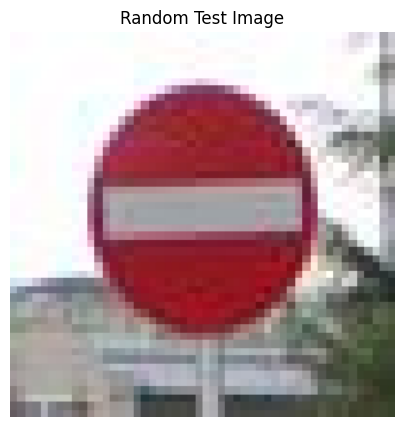

Image: 42140.jpg
Actual class: NO_ENTRY
Predicted class: NO_ENTRY
Prediction confidence: 96.84%
Correct prediction: True


In [22]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Select a random image from the test folders
image_paths = [
    p for p in Path(TEST_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

image_path = random.choice(image_paths)

# Load the image using the same size as training
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)
img_array = tf.keras.utils.img_to_array(img)

# Predict
probabilities = model.predict(
    np.expand_dims(img_array, axis=0),
    verbose=0
)[0]

predicted_idx = int(np.argmax(probabilities))
predicted_class = CLASS_NAMES[predicted_idx]
confidence = float(probabilities[predicted_idx]) * 100

# Actual class comes from its parent folder
actual_class = image_path.parent.name

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Random Test Image")
plt.show()

print("Image:", image_path.name)
print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print(f"Prediction confidence: {confidence:.2f}%")
print("Correct prediction:", actual_class == predicted_class)

In [23]:
top3_indices = np.argsort(probabilities)[-3:][::-1]

print("Top 3 predictions:")
for idx in top3_indices:
    print(f"{CLASS_NAMES[idx]}: {probabilities[idx] * 100:.2f}%")

Top 3 predictions:
NO_ENTRY: 96.84%
TRUCK_PROHIBITED: 0.58%
BULLOCK_PROHIBITED: 0.51%


In [20]:
import os
import json
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "custom_cnn_baseline.keras")
CLASS_PATH = os.path.join(MODEL_DIR, "class_names.json")

# Save the complete Keras model
model.save(MODEL_PATH)

# Save the class names in the correct prediction order
with open(CLASS_PATH, "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, indent=4, ensure_ascii=False)

print("Model saved:", MODEL_PATH)
print("Class names saved:", CLASS_PATH)
print("Model size (MB):", round(os.path.getsize(MODEL_PATH) / (1024**2), 2))

Model saved: /content/drive/MyDrive/Traffic_Sign_Project/models/custom_cnn_baseline.keras
Class names saved: /content/drive/MyDrive/Traffic_Sign_Project/models/class_names.json
Model size (MB): 5.0
